In [53]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import joblib

In [54]:
X_train = pd.read_csv(
    "../data/processed/X_train_processed.csv"
)

X_test = pd.read_csv(
    "../data/processed/X_test_processed.csv"
)

y_train = pd.read_csv(
    "../data/processed/y_train.csv"
).squeeze()

y_test = pd.read_csv(
    "../data/processed/y_test.csv"
).squeeze()

In [55]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)


(5634, 45)
(1409, 45)
(5634,)
(1409,)


In [56]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [57]:
logistic_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [58]:
y_pred = logistic_model.predict(X_test)


In [59]:
y_pred[:10]

array([1, 0, 0, 1, 0, 0, 0, 0, 0, 0])

In [60]:
accuracy = accuracy_score(
    y_test,
    y_pred
)
print(accuracy)

0.8211497515968772


In [61]:
precision = precision_score(
    y_test,
    y_pred
)

recall = recall_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred
)


print(precision)
print(recall)
print(f1)

0.6850152905198776
0.6005361930294906
0.64


In [62]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.86      0.90      0.88      1036
           1       0.69      0.60      0.64       373

    accuracy                           0.82      1409
   macro avg       0.77      0.75      0.76      1409
weighted avg       0.82      0.82      0.82      1409



In [63]:
cm = confusion_matrix(
    y_test,
    y_pred
)
print(cm)

[[933 103]
 [149 224]]


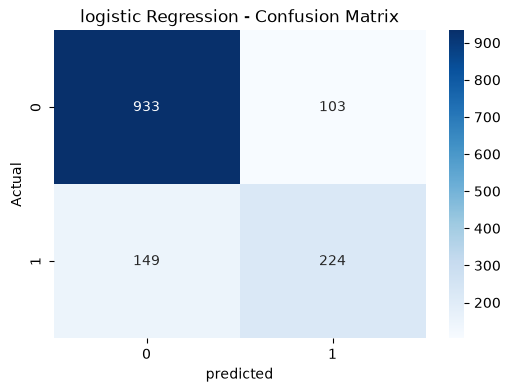

In [64]:
plt.figure(figsize=(6, 4))
sns.heatmap(cm,
            annot=True,
            fmt="d",
            cmap="Blues"
            )
plt.xlabel("predicted")
plt.ylabel("Actual")
plt.title("logistic Regression - Confusion Matrix")
plt.show()

In [65]:
y_proba = logistic_model.predict_proba(X_test)[:,1]
print(y_proba)

[0.6911393  0.06217334 0.00462818 ... 0.05114455 0.01342188 0.49291708]


In [66]:
roc_auc = roc_auc_score(
    y_test,
    y_proba
)
print("Roc-AUC:", roc_auc)

Roc-AUC: 0.8621230863187967


In [67]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_proba
)


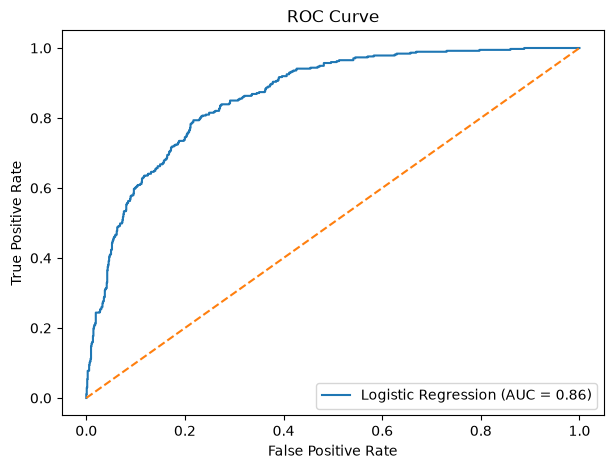

In [68]:
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.2f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()
plt.show()

In [69]:
decision_tree_model = DecisionTreeClassifier(random_state=42)


In [70]:
decision_tree_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [71]:
y_pred_dt = decision_tree_model.predict(X_test)

In [72]:
y_pred_dt[:10]

array([1, 0, 0, 0, 0, 1, 0, 0, 0, 0])

In [73]:
accuracy_dt = accuracy_score(
    y_test,
    y_pred_dt
)
print(accuracy_dt)

0.7154009936124911


In [74]:
precision_dt = precision_score(
    y_test,
    y_pred_dt
)

recall_dt = recall_score(
    y_test,
    y_pred_dt
)

f1_dt = f1_score(
    y_test,
    y_pred_dt
)


print(precision_dt)
print(recall_dt)
print(f1_dt)

0.4641025641025641
0.48525469168900803
0.4744429882044561


In [75]:
y_proba_dt = decision_tree_model.predict_proba(X_test)[:,1]
print(y_pred_dt)

[1 0 0 ... 0 0 0]


In [76]:
roc_auc_dt = roc_auc_score(
    y_test,
    y_proba_dt
)
print(roc_auc_dt)

0.6429076050389724


In [77]:
random_forest_model=RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [78]:
random_forest_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [79]:
y_pred_rf=random_forest_model.predict(X_test)

In [80]:
y_pred_rf[:10]

array([1, 0, 0, 1, 0, 0, 0, 0, 0, 0])

In [81]:
accuracy_rf = accuracy_score(
    y_test,
    y_pred_rf
    
)
print(accuracy_rf)

0.7970191625266146


In [82]:
precision_rf = precision_score(
    y_test,
    y_pred_rf
)

recall_rf = recall_score(
    y_test,
    y_pred_rf
)

f1_rf = f1_score(
    y_test,
    y_pred_rf
)

print("Precision:", precision_rf)
print("Recall:", recall_rf)
print("F1 Score:", f1_rf)

Precision: 0.6629213483146067
Recall: 0.4745308310991957
F1 Score: 0.553125


In [83]:
y_proba_rf = random_forest_model.predict_proba(X_test)[:,1]

In [84]:
roc_auc_rf = roc_auc_score(
    y_test,
    y_pred_rf
)
print(roc_auc_rf)

0.6938291221133044


In [85]:
gradient_boosting_model = GradientBoostingClassifier(
    random_state=42
)

In [86]:
gradient_boosting_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [87]:
y_pred_gb = gradient_boosting_model.predict(X_test)

In [88]:
y_pred_gb[:10]

array([1, 0, 0, 1, 0, 0, 0, 0, 0, 0])

In [89]:
accuracy_gb=accuracy_score(
    y_test,
    y_pred_gb
    )
print(accuracy_gb)

0.8076650106458482


In [90]:
precision_gb = precision_score(
    y_test,
    y_pred_gb
)

recall_gb = recall_score(
    y_test,
    y_pred_gb
)

f1_gb = f1_score(
    y_test,
    y_pred_gb
)

print("Precision:", precision_gb)
print("Recall:", recall_gb)
print("F1 Score:", f1_gb)

Precision: 0.6746575342465754
Recall: 0.5281501340482574
F1 Score: 0.5924812030075188


In [91]:
y_proba_gb = gradient_boosting_model.predict_proba(X_test)[:,1]

In [92]:
roc_auc_gb = roc_auc_score(
    y_test,
    y_pred_gb
)
print(roc_auc_gb)

0.7182256461747079


In [93]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    
    "Accuracy": [
        accuracy,
        accuracy_dt,
        accuracy_rf,
        accuracy_gb
    ],
    
    "Precision": [
        precision,
        precision_dt,
        precision_rf,
        precision_gb
    ],
    
    "Recall": [
        recall,
        recall_dt,
        recall_rf,
        recall_gb
    ],
    
    "F1 Score": [
        f1,
        f1_dt,
        f1_rf,
        f1_gb
    ],
    
    "ROC-AUC": [
        roc_auc,
        roc_auc_dt,
        roc_auc_rf,
        roc_auc_gb
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.821150,0.685015,0.600536,0.640000,0.862123
1,Decision Tree,0.715401,0.464103,0.485255,0.474443,0.642908
2,Random Forest,0.797019,0.662921,0.474531,0.553125,0.693829
3,Gradient Boosting,0.807665,0.674658,0.528150,0.592481,0.718226


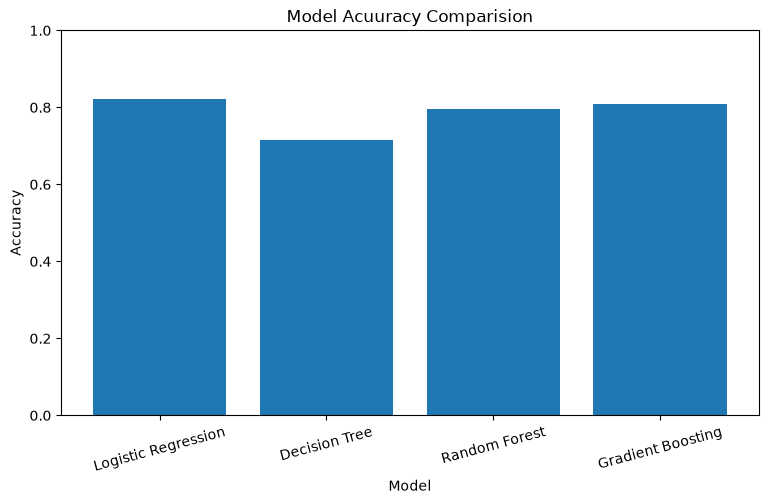

In [94]:
plt.figure(figsize=(9,5))
plt.bar(
    model_comparison["Model"],
    model_comparison["Accuracy"] 
)
plt.title("Model Acuuracy Comparision")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.show()

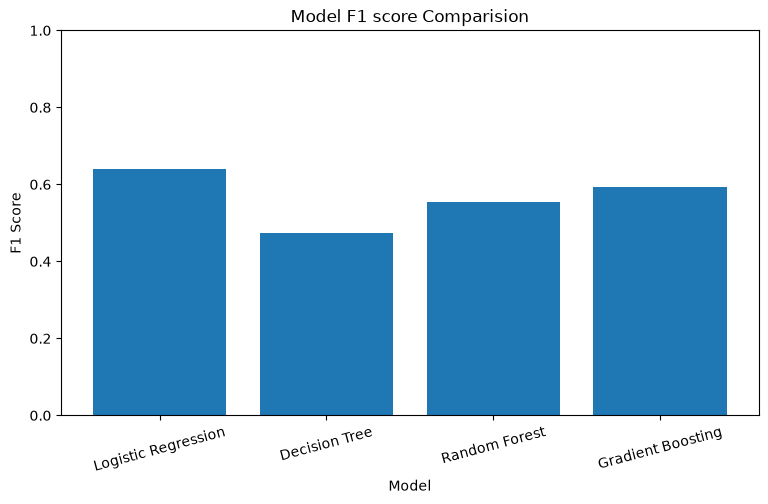

In [95]:
plt.figure(figsize=(9,5))
plt.bar(
    model_comparison["Model"],
    model_comparison["F1 Score"] 
)
plt.title("Model F1 score Comparision")
plt.xlabel("Model")
plt.ylabel("F1 Score")
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.show()

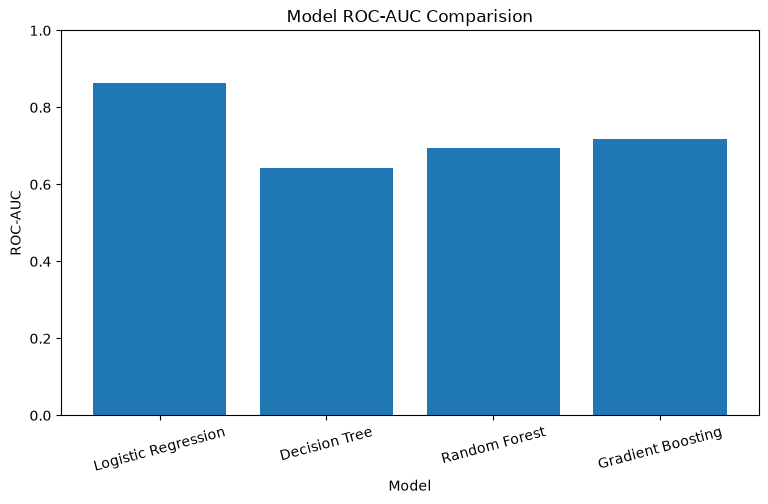

In [96]:
plt.figure(figsize=(9,5))
plt.bar(
    model_comparison["Model"],
    model_comparison["ROC-AUC"] 
)
plt.title("Model ROC-AUC Comparision")
plt.xlabel("Model")
plt.ylabel("ROC-AUC")
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.show()

## GridSearch


In [97]:
from sklearn.model_selection import GridSearchCV
logistic_model=LogisticRegression(
    max_iter=1000,
    random_state=42
)
param_grid = {
    "C":[0.01, 0.1, 1, 10, 100],
    "solver":["liblinear", "lbfgs"]
}

grid_search = GridSearchCV(
    estimator=logistic_model,
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)
grid_search.fit(
    X_train,
    y_train
)
print("Best Parameters:")
print(grid_search.best_params_)
print("\nBest Cross-Validation ROC-AUC:")
print(grid_search.best_score_)

# 7. Get best LogisticRegression model
best_logistic = grid_search.best_estimator_

y_pred_tuned = best_logistic.predict(X_test)
# 9. Churn probability
y_proba_tuned = best_logistic.predict_proba(X_test)[:, 1]

#10. Evaluation metrics
accuracy_tuned = accuracy_score(y_test, y_pred_tuned)

precision_tuned = precision_score(
    y_test,
    y_pred_tuned
)

recall_tuned = recall_score(
    y_test,
    y_pred_tuned
)

f1_tuned = f1_score(
    y_test,
    y_pred_tuned
)

roc_auc_tuned = roc_auc_score(
    y_test,
    y_proba_tuned
)
print("\n===== Tuned Logixtic regression Results =====")

print("Accuracy :", accuracy_tuned)
print("Precision:", precision_tuned)
print("Recall   :", recall_tuned)
print("F1 Score :", f1_tuned)
print("ROC-AUC  :", roc_auc_tuned)

print(
    classification_report(
        y_test,
        y_pred_tuned
    )
)

cm_tuned = confusion_matrix(
    y_test,
    y_pred_tuned
)

print(cm_tuned)


# 14. Save tuned model
joblib.dump(
    logistic_model,
    "../models/logictic_regession_tuned.pkl"
)


Best Parameters:
{'C': 100, 'solver': 'liblinear'}

Best Cross-Validation ROC-AUC:
0.8410422330452068

===== Tuned Logixtic regression Results =====
Accuracy : 0.8197303051809794
Precision: 0.6842105263157895
Recall   : 0.5924932975871313
F1 Score : 0.6350574712643678
ROC-AUC  : 0.8616650449760369
              precision    recall  f1-score   support

           0       0.86      0.90      0.88      1036
           1       0.68      0.59      0.64       373

    accuracy                           0.82      1409
   macro avg       0.77      0.75      0.76      1409
weighted avg       0.81      0.82      0.82      1409

[[934 102]
 [152 221]]


['../models/logictic_regession_tuned.pkl']

In [98]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
import joblib
rf = RandomForestClassifier(
    random_state=42
)

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

grid_search.fit(
    X_train,
    y_train
)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(grid_search.best_score_)

best_rf = grid_search.best_estimator_

y_pred_tuned = best_rf.predict(X_test)

y_proba_tuned = best_rf.predict_proba(X_test)[:, 1]

accuracy_tuned = accuracy_score(y_test, y_pred_tuned)

precision_tuned = precision_score(
    y_test,
    y_pred_tuned
)

recall_tuned = recall_score(
    y_test,
    y_pred_tuned
)

f1_tuned = f1_score(
    y_test,
    y_pred_tuned
)

roc_auc_tuned = roc_auc_score(
    y_test,
    y_proba_tuned
)



print("\nRandom Forest Results ")

print("Accuracy :", accuracy_tuned)
print("Precision:", precision_tuned)
print("Recall   :", recall_tuned)
print("F1 Score :", f1_tuned)
print("ROC-AUC  :", roc_auc_tuned)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_tuned
    )
)

cm_tuned = confusion_matrix(
    y_test,
    y_pred_tuned
)

print("\nConfusion Matrix:")
print(cm_tuned)

joblib.dump(
    best_rf,
    "../models/random_forest_tuned.pkl"
)

print("\nTuned Random Forest model saved successfully.")

Best Parameters:
{'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}

Best Cross-Validation ROC-AUC:
0.8386490365212922

Random Forest Results 
Accuracy : 0.8119233498935415
Precision: 0.6875
Recall   : 0.5308310991957105
F1 Score : 0.5990922844175491
ROC-AUC  : 0.8605665220946721

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.91      0.88      1036
           1       0.69      0.53      0.60       373

    accuracy                           0.81      1409
   macro avg       0.77      0.72      0.74      1409
weighted avg       0.80      0.81      0.80      1409


Confusion Matrix:
[[946  90]
 [175 198]]

Tuned Random Forest model saved successfully.
